# Does the wrapper match its reference, and what does that not prove?

**Question:** Does product CrossGradient reproduce pinned SimPEG on identical inputs, and where does that comparison stop?

**Level 3 — same-input method comparison**  
**Prerequisites:** joint objective, tensor meshes, active-cell maps and numerical parity; 40 min.

## Objectives

Run the repository wrapper and SimPEG CrossGradient with the same plan, active cells, property vectors, scales and coupling length. Compare objective and derivatives, then distinguish software parity from convergence, prediction and field validity.

## Setup

Install exact dependencies:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

Both implementations receive the same authored twelve-cell control; the plan and model order are fixed before either calculation.

## Data

The shared input is a deterministic, authored local control with twelve active cells, declared gravity and magnetic receiver geometry, bounded property vectors and uncertainty metadata. It contains no field observations. Both the product wrapper and reference use these same arrays, so the comparison tests numerical implementation rather than data selection.

## Method

Cross-gradient regularization penalizes discordant orientations of property gradients. Identical inputs let differences be attributed to adapter or convention rather than data selection. Objective, gradient and Hessian-vector product are compared. This is a focused parity test on one mesh and parameterization, not an independent inversion benchmark: both calls evaluate the same prior, and neither fits observed gravity or magnetic data.

A useful reference comparison names implementation and version, aligns discretization and units, uses identical inputs and states what remains untested. This comparison does so for SimPEG. It does not compare alternative priors, optimizers or field results. Exact agreement can coexist with poor resolution, nonunique models, a false shared-structure hypothesis or poor held-out prediction.


In [1]:
# Import the pinned physical evaluator and show the runtime versions.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### Authored control shared by both methods

The twelve-cell control fixes survey metadata, property bounds and scales, and deterministic mesh geometry. It supplies a precise comparison input. Density and susceptibility are authored, not estimated, so the test says nothing about what a real survey supports. Identical inputs matter: otherwise differences could arise from active masks, vector order or units instead of implementation.


In [2]:
# Define a small authored ENU control and its declared physical scales.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Acquisition frame and uncertainty

Gravity and magnetic coordinates share local ENU, but magnetic receivers are shifted east and retain distinct physical units. Independent Gaussian declarations describe the synthetic request; no measured data or noise realizations are inverted here. Covariance, topography, remanence and coordinate transforms require separate validation before interpreting field results.


In [3]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### Mesh and parameterization contract

The plan-built tensor mesh, active mask, x-fast ordering and property scales define the reference. Both implementations must use those choices for meaningful parity. A permutation may preserve an aggregate norm while changing cellwise values; scale mismatches can mimic defects. This control covers one compact topology, not every mesh or boundary treatment.


In [4]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Plan before reference evaluation

The planner validates the request and normalizes wrapper inputs. The same plan supplies mesh and support to the direct SimPEG call. This makes model ordering and scales explicit. It remains a software-contract check, not evidence that the control represents geology or that its prior is appropriate.


In [5]:
# Validate units, active cells, and source groups before evaluating a joint structural quantity.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("authored active cells", int(physical_plan["mesh"]["active"].sum()), "receiver count", len(receivers))


authored active cells 12 receiver count 6


### Step 1 — evaluate the product wrapper

Retain objective, gradient and Hessian-vector product for the fixed model pair. No optimizer updates the properties and no data residual is minimized. The plan digest records the precise input contract for the reference calculation.


In [6]:
# Run the product wrapper on the physical control.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("product objective", r["objective"], "plan", r["plan_sha256"])


product objective 0.012770248999752326 plan c62903164d0f129d95137ffe16f334e3cf0d936d26f1f8fa04c6d4da3da9563c


### Step 2 — construct the reference mesh

Build SimPEG's mesh and active-cell map from the normalized plan. Confirm identical cells and vector ordering for each property. A permutation can preserve a norm yet alter local results; scale convention differences can also resemble implementation errors.


In [7]:
# Re-run the public planner before building the independent SimPEG reference.
physical_plan_check = planner.plan_joint_survey(physical_request)
assert physical_plan_check["plan_sha256"] == physical_plan["plan_sha256"]
from discretize import TensorMesh
from simpeg import maps
from simpeg.regularization import CrossGradient

mesh = TensorMesh(
    [physical_plan_check["mesh"][k] for k in ("hx_m", "hy_m", "hz_m")],
    origin=physical_plan_check["mesh"]["origin_m"],
)
print("same-plan tensor cells", mesh.nC)


same-plan tensor cells 12


### Step 3 — run pinned CrossGradient

Evaluate SimPEG with the same density and susceptibility vectors, scales and coupling length. It is a separate software path, not an independent physical experiment: inputs and regularization hypothesis are shared. Interpret it as parity for this contract.


In [8]:
# Compute the reference objective using the same scales and active mask.
wires = maps.Wires(("density", physical_n), ("susceptibility", physical_n))
ref = CrossGradient(mesh, wires, active_cells=physical_plan["mesh"]["active"], approx_hessian=False)
scales = np.r_[
    np.full(physical_n, physical_plan["prior"]["density"]["scale"]),
    np.full(physical_n, physical_plan["prior"]["susceptibility"]["scale"]),
]
x = np.r_[physical_rho, physical_chi] / scales
vol = mesh.cell_volumes[physical_plan["mesh"]["active"]]
factor = physical_plan["prior"]["coupling_length_m"] ** 4 / float(vol.sum())
reference_value = float(factor * ref(x))
print("direct SimPEG objective", reference_value)


direct SimPEG objective 0.012770248999752326


### Step 4 — compare objective and derivatives

Compare scalar objective, full gradient and Hessian-vector components. Agreement to displayed precision exercises more of the calculation than matching one scalar. Yet the test covers only one point, direction and discretization. It establishes neither global equivalence nor optimizer behavior on another mesh.


In [9]:
# Recompute the wrapper Hessian action with the reversed physical direction.
reverse_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": -physical_direction,
    }
)
reverse_hv = np.asarray(reverse_result["exact_hessian_vector_physical"])
g = np.asarray(factor * ref.deriv(x) / scales)
hv = np.asarray(factor * ref.deriv2(x, physical_direction / scales) / scales)
print("objective absolute difference", abs(reference_value - r["objective"]))
print("gradient maximum difference", np.max(np.abs(g - r["gradient_physical"])))
print("Hessian-vector maximum difference", np.max(np.abs(hv - r["exact_hessian_vector_physical"])))
print("direction reversal maximum difference", np.max(np.abs(reverse_hv + r["exact_hessian_vector_physical"])))


objective absolute difference 0.0
gradient maximum difference 0.0
Hessian-vector maximum difference 0.0
direction reversal maximum difference 0.0


### Step 5 — retain the cellwise view

Inspect contributions by active cell alongside aggregate parity. Local values may reveal indexing errors hidden by one scalar. They are not a spatial section, data residual, resolution measure or contact estimate. Report diagnostic value together with these limits.


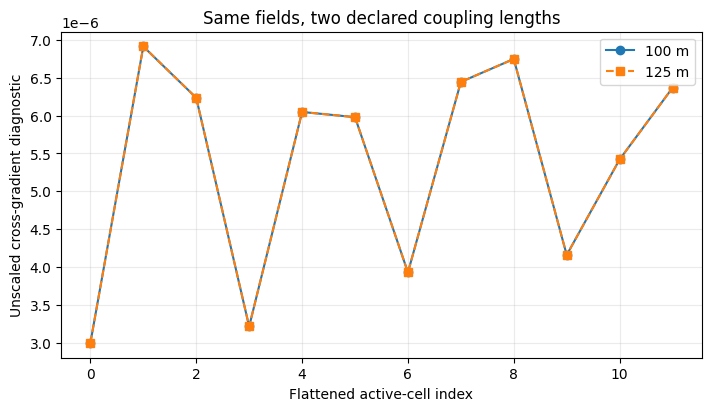

baseline and perturbed objective 0.012770248999752326 0.031177365722051577


In [10]:
# Evaluate a 25 percent length perturbation on the unchanged property fields.
from copy import deepcopy

length_request = deepcopy(physical_request)
length_request["prior"]["coupling_length_m"] *= 1.25
length_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": length_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
d = np.asarray(r["cell_centre_cross_gradient"])
d_length = np.asarray(length_result["cell_centre_cross_gradient"])
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(np.arange(len(d)), d, "o-", label="100 m")
ax.plot(np.arange(len(d_length)), d_length, "s--", label="125 m")
ax.set(
    xlabel="Flattened active-cell index",
    ylabel="Unscaled cross-gradient diagnostic",
    title="Same fields, two declared coupling lengths",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print("baseline and perturbed objective", r["objective"], length_result["objective"])


The figure reports recomputed wrapper/reference values for this authored control. Read axes as numerical agreement, not observed-data fit. Models are prescribed and no inversion runs. The plot supports a narrow implementation claim; it leaves resolution, uncertainty and prediction unanswered.


## Comparison

SimPEG CrossGradient is a published structural regularizer in an open geophysical inversion framework. Its pinned direct call is a relevant implementation reference. Sharing the plan-built mesh, active cells, vectors, scales and length controls major sources of numerical mismatch. The SimPEG tutorial provides method context; it does not independently validate this repository or the present control.

This comparison does not show that cross-gradient is better than independent inversions, petrophysical coupling or another structural prior. It does not show uniqueness. The term can be weak where a property is flat and insensitive to some amplitude differences. Gradients may align even though one modality has poor resolution. If the shared-structure assumption is false, the prior can transfer a plausible-looking boundary into a model unsupported by the weaker data.

Parity is one gate in an evidence chain: contract validation, numerical parity, forward fit, convergence and held-out prediction, resolution or uncertainty analysis, then geological corroboration. This notebook measures parity only. It compares no independent solver family and makes no field-readiness claim.


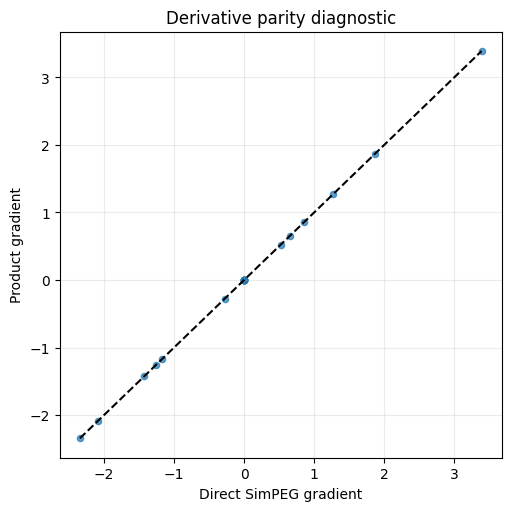

In [11]:
# Compare product and direct SimPEG gradient components.
fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
ax.scatter(g, r["gradient_physical"], s=20, alpha=0.7)
lo = min(g.min(), np.min(r["gradient_physical"]))
hi = max(g.max(), np.max(r["gradient_physical"]))
ax.plot([lo, hi], [lo, hi], "k--")
ax.set(xlabel="Direct SimPEG gradient", ylabel="Product gradient", title="Derivative parity diagnostic")
ax.grid(alpha=0.25)
plt.show()


### Figure interpretation

Wrapper and pinned SimPEG points lie on the identity line; the maximum recorded difference is zero at displayed precision. This supports parity for the tested mesh, order and scales. It does not cover every topology or version, and neither implementation used observations. Equal outputs cannot prove convergence, prediction, resolution, uniqueness or validity of the shared-structure hypothesis.




## Results

**Answer:** On the authored twelve-cell control, maximum wrapper/reference differences in objective, gradient and Hessian-vector product are zero at displayed precision. This supports parity only for this tested contract.

## Summary

A same-input reference comparison isolates software behavior. Its scientific scope is narrow: no observations are fitted, no model is recovered, and equality does not support predictive or field claims.

## References

- [SimPEG cross-gradient tutorial](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`
